In [4]:
import skimage
import skimage.io
import skimage.transform
import pathlib
import numpy as np
import utils
import matplotlib.pyplot as plt
image_dir = pathlib.Path("images")
impaths = [
    image_dir.joinpath("page1.png"),
    image_dir.joinpath("page2.png"),
    image_dir.joinpath("page4.png"),
    image_dir.joinpath("page6.png"),
    image_dir.joinpath("page7.png"),
    image_dir.joinpath("page8.png"),
]

In [ ]:
def create_binary_image(im):
    """Creates a binary image from a greyscale image "im"

    Args:
        im ([np.ndarray, np.float]): [An image of shape [H, W] in the range [0, 1]]

    Returns:
        [np.ndarray, bool]: [A binary image]
    """

    # START YOUR CODE HERE ### (You can change anything inside this block)

    kernel = np.array([
        [-1, 0, 1],
        [-2, 0, 2],
        [-1, 0, 1]
    ])

    orig_im = im.copy()
    orig_shape = im.shape
    orig_kernel = kernel.copy()
    conv_result = np.zeros_like(im, dtype=float)
    kernel = np.flipud(np.fliplr(kernel))     # flipping the kernel to apply a convolution
    kernel_half_size = len(kernel)//2
    kernel = np.pad(kernel, orig_shape)
    new_kernel_half_size = len(kernel)//2

    for i in range(len(im)):
        for j in range(len(im[i])):
            # Convolution so going from bottom to top and from right to left in the kernel
            for k in range(-kernel_half_size, kernel_half_size+1):
                for l in range(-kernel_half_size, kernel_half_size+1):
                    try:
                        conv_result[i, j] += kernel[new_kernel_half_size+k, new_kernel_half_size+l]*im[i+k, j+l]
                    except IndexError:
                        # Index out of bound: returning zero (to imitate a zero padding)
                        pass

    threshold = 0.5
    binary_im = (conv_result > threshold)

    ### END YOUR CODE HERE ###
    return binary_im

Found angle: -0.25
Found angle: -0.25
Found angle: -63.43
Found angle: -0.25
Found angle: 0.25
Found angle: -0.25
Saving image to: image_processed/task4d.png


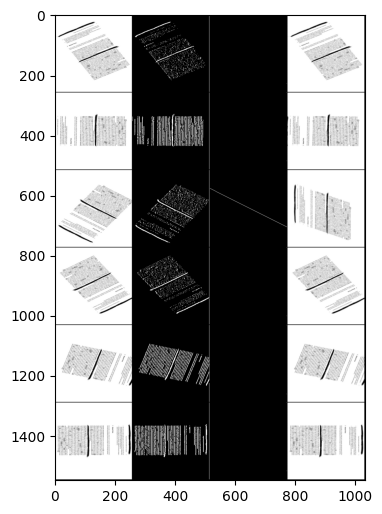

In [32]:
if __name__ == "__main__":
    # NO NEED TO EDIT THE CODE BELOW.
    verbose = True
    plt.figure(figsize=(4, 12))    
    plt.tight_layout()
    images_to_visualize = []
    for i, impath in enumerate(impaths):
        im = utils.read_im(str(impath))
        im_binary = create_binary_image(im)
        assert im_binary.dtype == bool,\
            f"Expected the image to be of dtype bool, got {im_binary.dtype}"
        angles, distances = utils.find_angle(im_binary)
        angle = 0
        if len(angles) > 0:
            angle = angles[0] * 180 / np.pi
        print(f"Found angle: {angle:.2f}")
        hough_im = utils.create_hough_line_image(im, angles, distances)
        rotated = skimage.transform.rotate(im, angle, cval=im.max())
        images_to_visualize.extend(
            [im, im_binary, hough_im, rotated]
        )
    image = utils.np_make_image_grid(images_to_visualize, nrow=len(impaths))
    utils.save_im("task4d.png", image)
    plt.imshow(image, cmap="gray")